# CyberShield AI - Hospital SOC: Full-Stack Demo

Simulates a hospital network, detects incidents with explainable rules, then **fuses three evidence sources into the team's 9-column contract**: the trained **network model** (Hanan), the **log-anomaly model** (Bardia) and **threat intelligence** (Nour). Finally it starts the authenticated FastAPI backend.

Run with **Kernel -> Restart & Run All** from inside the repo. Cells degrade gracefully and the Readiness Report at the end says what worked.

## What is real, and what is a bridge (read before presenting)
| Piece | Status |
|---|---|
| Rule engine, simulation, scoring, API | Real, all in `soc/` |
| Network model | Real trained model (`models/model_unsw.pkl`, Snap ML). Without `snapml` (any non-LinuxONE laptop) `models/network_score.py` trains a scikit-learn twin from the same data on first use (~1 min, cached). Same features/threshold rule, ~92% test accuracy. |
| Network evidence on alerts | **Replay.** The simulator writes event logs, not packets, so each network-type alert is paired with a sample of held-out UNSW-NB15 attack flows and scored by the model (`models/network_evidence.py`). Real model, replayed traffic. |
| Log-anomaly model | Bardia's `LogRiskModel` (PCA reconstruction error). His HDFS and BGL bundles are used when present in `models/results_hdfs/` and `models/results_bgl/`. Hospital events are not HDFS/BGL events, so the alerts' `anomaly_score` comes from the same method fitted on the SOC's own event vocabulary (`models/log_anomaly.py`). |
| Fusion | `engine/fusion.py`. Rule score stays the floor; models can lift it by at most 0.10 and never lower it. |

## Cell 1: Setup
Finds the repo root, sets demo credentials, creates `data/assets.csv` if missing, installs dependencies (`snapml` is optional).

In [12]:
# 1. Setup: locate the repo, make sure config + data exist
import os, sys, subprocess, pathlib, csv, json, time

def find_root():
    """Find the repo root by looking for soc/service.py up the tree."""
    p = pathlib.Path.cwd().resolve()
    for d in [p, *p.parents]:
        if (d / "soc" / "service.py").exists():
            return d
    raise SystemExit("Open this notebook inside the Datathon-SOC repo (folder containing soc/).")

ROOT = find_root(); os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("✓ Repo root:", ROOT)

# Demo-only credentials (>=16 chars). Replace for anything real.
ANALYST = "demo-analyst-token-secure-12345"
os.environ["SOC_ANALYST_TOKEN"] = ANALYST
os.environ["SOC_VIEWER_TOKEN"]  = "demo-viewer-token-secure-67890"
os.environ["SOC_DB_PATH"] = str(ROOT / "data" / "demo_soc.db")
os.makedirs(ROOT / "data", exist_ok=True)

# data/ is gitignored, so recreate the asset inventory if it is missing
ASSETS_CSV = ROOT / "data" / "assets.csv"
if not ASSETS_CSV.exists():
    rows = [("EHR Server",5,"server",True,True),("Pharmacy System",5,"server",True,True),
            ("Infusion Pump Network",5,"medical_device",True,False),("MRI Scanner",4,"medical_device",True,False),
            ("Patient Monitor Network",5,"medical_device",True,False),("PACS Imaging",4,"server",True,True),
            ("Lab System",4,"server",True,True),("Domain Controller",5,"server",False,False),
            ("VPN Gateway",4,"network",False,False),("Finance System",3,"server",False,False),
            ("Nurse Workstation",3,"workstation",True,False),("Admin Office PC",2,"workstation",False,False)]
    with open(ASSETS_CSV,"w",newline="") as f:
        w=csv.writer(f)
        w.writerow(["asset_id","asset","criticality","type","department","subnet","patient_care","holds_phi","description","simulated"])
        for i,(n,c,t,pc,phi) in enumerate(rows,1):
            w.writerow([f"A{i:03d}",n,c,t,"Demo",f"10.{i}.0.0/24",pc,phi,"demo asset",True])
    print("✓ Created", ASSETS_CSV)
else:
    print("✓ Using existing", ASSETS_CSV)

# Install the (tiny) requirements; failure is not fatal if they are already installed
def pip(*args):
    return subprocess.run([sys.executable,"-m","pip","install","-q",*args],capture_output=True,text=True).returncode==0
print("✓ pip install requirements:", "ok" if pip("-r","requirements.txt") else "skipped (continuing)")
print("✓ pip install data/model packages:", "ok" if pip("-r","data_pipeline/requirements.txt") else "skipped (continuing)")
try:
    import snapml; print("✓ snapml available (original Snap ML model will be used)")
except ImportError:
    print("• snapml not installed -> scikit-learn twin of the network model will be used (fine for the demo)")

✓ Repo root: /home/ibm-user/Datathon-SOC
✓ Using existing /home/ibm-user/Datathon-SOC/data/assets.csv
✓ pip install requirements: ok
✓ pip install data/model packages: ok
✓ snapml available (original Snap ML model will be used)


## Cell 2: Simulate logs & run the rule engine
426 simulated logs -> ~20 alerts, each scored 1..10 with a visible breakdown.

In [13]:
# 2. Simulate logs and run the rule-based detection engine
from soc.assets import load_assets
from soc.config import load_settings
from soc.service import SocService

settings = load_settings()
assets = load_assets(ASSETS_CSV)
service = SocService(settings=settings, assets=assets)

# Simulate hospital logs and trigger detection rules
# benign=300 means 300 normal logs; the rest are crafted incidents (ransomware, insider abuse, etc.)
sim = service.simulate(seed=42, benign=300, replace=True)
print("✓ Simulation & detection summary:")
for k, v in sim.items():
    print(f"  {k}: {v}")

✓ Simulation & detection summary:
  seed: 42
  logs_inserted: 426
  logs_analysed: 426
  alerts_total: 20
  created: 20
  refreshed: 0


## Cell 3: Open alerts, highest risk first

In [14]:
# 3. Open alerts, highest risk first
import pandas as pd

items, total = service.db.query_alerts({"open_only": True}, sort="score_desc", limit=200)
df_alerts = pd.DataFrame(items)
print(f"✓ Found {total} open alerts")
if len(df_alerts) > 0:
    display(df_alerts[["id","rule_id","severity","score","title","asset"]].head(15))
else:
    print("  (no alerts)")

✓ Found 20 open alerts


,id,rule_id,severity,score,title,asset
0,121,RAN-001,critical,10,Mass file encryption activity,Lab System
1,122,RAN-003,critical,9,Ransom note created,Lab System
2,130,EHR-001,critical,8,Bulk patient-record access without care relati...,EHR Server
3,129,RAN-002,critical,8,Backups or shadow copies tampered with,Lab System
4,128,MAL-002,critical,8,Encoded PowerShell launched by an application,Lab System
5,127,DEV-002,critical,8,Unapproved remote-admin connection to a medica...,Infusion Pump Network
6,126,DEV-001,critical,8,Medical device communicating with the internet,Infusion Pump Network
7,125,PRIV-003,critical,8,Security audit log cleared,Domain Controller
8,124,PRIV-001,critical,8,Suspicious addition to a privileged group,Domain Controller
9,123,BF-003,critical,8,Successful login after repeated failures,VPN Gateway


## Cell 4: Threat intelligence -> `threat_flag`

In [15]:
# 4. Threat intelligence -> threat_flag
ti = None
try:
    sys.path.insert(0, str(ROOT / "data_pipeline"))
    import threat_intel as ti
    feed = ROOT / "data_pipeline" / "outputs" / "threat_urls.csv"
    if feed.exists():
        # Load threat URLs into the module's BAD_SET
        urls = pd.read_csv(feed)["url"].dropna().astype(str).str.strip()
        ti.BAD_SET.update(urls)
        print(f"✓ Threat-intel loaded {len(ti.BAD_SET)} indicators from {feed.name}")
    else:
        ti.load_all()
        print(f"✓ Threat-intel loaded {len(ti.BAD_SET)} indicators from openphish/urlhaus feeds")
    
    # Self-check
    sample = next(iter(ti.BAD_SET), None)
    bad_score = ti.is_known_bad(sample)
    clean_score = ti.is_known_bad("http://example.invalid/ok")
    print(f"  Self-check: known-bad URL -> {bad_score} | clean URL -> {clean_score}")
except Exception as e:
    print(f"⚠ Threat intel unavailable (will use SOC's own IOC facts): {e}")

known_bad = ti.is_known_bad if ti is not None else None

✓ Threat-intel loaded 20000 indicators from threat_urls.csv
  Self-check: known-bad URL -> 1 | clean URL -> 0


## Cell 5: Network model on real UNSW-NB15 flows (independent accuracy check)
Shows the trained model's accuracy on 2,000 random held-out flows. `backend` says whether Snap ML or the scikit-learn twin ran.

In [16]:
# 5. Trained network model evidence on real UNSW-NB15 flows
model_status = {}
try:
    import numpy as np
    from models import network_score as ns
    flows = pd.read_csv(ns.TEST_CSV).sample(2000, random_state=1)
    bundle = ns._load()                       # snapml model, or scikit-learn twin (trains once, ~1 min)
    scores = ns.score_batch(flows)
    acc = float(((scores >= bundle["threshold"]).astype(int) == flows["label_binary"].values).mean())
    model_status = {"ok": True, "backend": bundle.get("backend"), "accuracy": round(acc, 4),
                    "threshold": bundle["threshold"], "n_flows": len(flows),
                    "score_min": float(scores.min()), "score_max": float(scores.max())}
    print("✓ Network model OK:")
    for k, v in model_status.items():
        print(f"  {k}: {v}")
except Exception as e:
    model_status = {"ok": False, "reason": str(e)}
    print("⚠ Network model NOT scored here:", e)

✓ Network model OK:
  ok: True
  backend: snapml
  accuracy: 0.9225
  threshold: 0.8
  n_flows: 2000
  score_min: 0.0
  score_max: 1.0


## Cell 6: Log-anomaly model (Bardia)
Bardia's `LogRiskModel` (PCA reconstruction error; 0.25 = WARNING, 0.5 = CRITICAL) is used three ways:
**(a)** HDFS: his saved metrics, plus his trained bundle `results_hdfs/log_model_pca.joblib` scoring real HDFS blocks when that file is in the repo.
**(b)** BGL: his bundle `results_bgl/log_model_bgl.joblib` on real supercomputer logs (rebuilt from `bgl_events.csv.gz` only if the file is missing).
**(c)** The hospital's own logs: windows are (asset, 15 min) event-count vectors. HDFS/BGL event IDs are not hospital events, so (c) uses the same method with a bundle fitted on the SOC's event vocabulary (benign-only simulated days; thresholds tuned on separate labelled days; the demo day, seed 42, was never used for training). This (c) score is what feeds `anomaly_score` in the fusion cell.


In [17]:
# 6. Log-anomaly model (Bardia's LogRiskModel)
import joblib
from models import log_anomaly as la
LogRiskModel = la.LogRiskModel
MODELS = ROOT / "models"
anomaly, anomaly_status = None, {}
bardia = {}   # which of Bardia's own artifacts were actually used

# (a) HDFS: Bardia's trained PCA bundle (if present) + his saved evaluation metrics
try:
    m = json.load(open(MODELS / "results_hdfs" / "metrics_pca.json"))
    c = m["critical"]
    print(f"✓ (a) HDFS saved metrics (his held-out test): precision {c['precision']:.2f} | recall {c['recall']:.2f} | "
          f"F1 {c['f1']:.2f} | AUC {m['roc_auc']:.3f}")
    hb = MODELS / "results_hdfs" / "log_model_pca.joblib"
    if hb.exists():
        hdfs = LogRiskModel(str(hb))
        blocks = pd.read_csv(MODELS / "hdfs_sequences.csv.gz").sample(2000, random_state=1)
        levels = pd.Series([hdfs.score_events(str(e).split())["level"] for e in blocks["Events"]]).value_counts()
        print(f"  his trained bundle scored 2,000 real HDFS blocks live: {levels.to_dict()}")
        bardia["hdfs_bundle"] = True
    else:
        print("  (models/results_hdfs/log_model_pca.joblib not found: showing his saved metrics only)")
except Exception as e:
    print("⚠ (a) HDFS part skipped:", e)

# (b) BGL: his original data (uses his bundle if it is in models/results_bgl/, else rebuilds one)
try:
    had_bundle = os.path.exists(la.BGL_BUNDLE)
    bgl = joblib.load(la.BGL_BUNDLE) if had_bundle else la.train_bgl_bundle(verbose=False)
    if "test" in bgl:
        t = bgl["test"]
        print(f"✓ (b) BGL held-out windows: {t['windows']} ({t['anomalous']} anomalous) | recall {t['recall']:.2f} | "
              f"precision {t['precision']:.2f} | AUC {t['auc']:.2f}")
    else:   # Bardia's own bundle carries no test summary: read his saved metrics instead
        w = json.load(open(MODELS / "results_bgl" / "metrics_bgl.json"))["window_level_test"]
        c = w["critical"]
        print(f"✓ (b) BGL saved metrics (his held-out test): recall {c['recall']:.2f} | precision {c['precision']:.2f} | "
              f"AUC {w['roc_auc']:.2f}")
    probe = LogRiskModel(la.BGL_BUNDLE).score_events([1, 2, 3])
    print(f"  bundle loads in LogRiskModel and scores: {probe['level']} ({probe['score']})")
except Exception as e:
    print("⚠ (b) BGL part skipped:", e)

# (c) SOC: same method on the hospital's own logs, one (asset, 15 min) window at a time
try:
    anomaly = la.SocAnomalyScorer()
    anomaly.fit_logs(service.db.all_logs_for_detection())
    y = np.array([anomaly.window_labels[k] for k in anomaly.window_results])
    p = np.array([anomaly.window_results[k]["score"] for k in anomaly.window_results])
    for name, thr in (("WARNING", la.WARNING_AT), ("CRITICAL", la.CRITICAL_AT)):
        pred = p >= thr
        print(f"✓ (c) SOC demo day, >= {name}: caught {int((pred & (y == 1)).sum())}/{int(y.sum())} incident windows, "
              f"{int((pred & (y == 0)).sum())} false-alarm windows out of {int((y == 0).sum())} normal")
    anomaly_status = {"ok": True}
except Exception as e:
    anomaly_status = {"ok": False, "reason": str(e)}
    print("(c) Log-anomaly model unavailable (anomaly_score will be 0.0):", e)


✓ (a) HDFS saved metrics (his held-out test): precision 0.89 | recall 0.97 | F1 0.93 | AUC 0.996


/opt/venv/lib64/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.4.1.post1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


  his trained bundle scored 2,000 real HDFS blocks live: {'NORMAL': 1900, 'CRITICAL': 67, 'WARNING': 33}
✓ (b) BGL saved metrics (his held-out test): recall 0.75 | precision 0.30 | AUC 0.79
  bundle loads in LogRiskModel and scores: NORMAL (0.0432)
✓ (c) SOC demo day, >= WARNING: caught 21/23 incident windows, 43 false-alarm windows out of 195 normal
✓ (c) SOC demo day, >= CRITICAL: caught 16/23 incident windows, 5 false-alarm windows out of 195 normal


/opt/venv/lib64/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.4.1.post1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## Cell 7: Fuse everything -> `engine/alerts.csv`
`engine/fusion.py`: network_score (model on replayed flows, network-type alerts only) + anomaly_score (log model) + threat_flag. `risk_score` = rule score/10, lifted by at most 0.10 where the models agree; never lowered. Extra provenance columns (`risk_basis`, `network_source`, `anomaly_why`) are shown here but only the 9 contract columns are written to the CSV.

In [18]:
# 7. Fuse alerts -> engine/alerts.csv
from shared.schema import ALERT_COLUMNS
from engine import fusion

replay = None
try:
    from models.network_evidence import FlowReplay
    replay = FlowReplay()
except Exception as e:
    print(f"⚠ Network model unavailable, network_score falls back to rule confidence: {e}")

all_items, _ = service.db.query_alerts({}, sort="score_desc", limit=5000)
df_fused, problems = fusion.build_alert_table(all_items, service.assets, service.hash_key,
                                              anomaly=anomaly, flow_replay=replay, is_known_bad=known_bad)
print("✓ No contract violations" if not problems else f"✗ Contract violations: {problems[:5]}")
os.makedirs(ROOT / "engine", exist_ok=True)
fusion.write_contract_csv(df_fused, ROOT / "engine" / "alerts.csv")
print(f"✓ Wrote engine/alerts.csv ({len(df_fused)} rows, 9 contract columns)")
display(df_fused[["rule_id","asset","network_score","anomaly_score","threat_flag","rule_risk","risk_score",
                  "risk_basis","anomaly_why"]].head(20))
print(df_fused["recommended_action"].str.slice(0, 40).value_counts().to_string())

✓ No contract violations
✓ Wrote engine/alerts.csv (20 rows, 9 contract columns)


,rule_id,asset,network_score,anomaly_score,threat_flag,rule_risk,risk_score,risk_basis,anomaly_why
0,RAN-001,Lab System,0.000,1.000,0,1.0,1.00,rule,"network_connection|internal, file_modified_burst"
1,RAN-003,Lab System,0.000,1.000,0,0.9,0.90,rule,"network_connection|internal, file_modified_burst"
2,EHR-001,EHR Server,0.000,0.307,0,0.8,0.80,rule,ehr_record_access
3,RAN-002,Lab System,0.000,1.000,0,0.8,0.80,rule,"network_connection|internal, file_modified_burst"
4,MAL-002,Lab System,0.000,0.134,0,0.8,0.80,rule,process_start
5,DEV-002,Infusion Pump Network,0.998,0.580,0,0.8,0.90,rule + model lift,"device_network_connection|inbound, device_netw..."
6,DEV-001,Infusion Pump Network,0.997,0.580,1,0.8,0.90,rule + model lift,"device_network_connection|inbound, device_netw..."
7,PRIV-003,Domain Controller,0.000,0.501,0,0.8,0.80,rule,audit_log_cleared
8,PRIV-001,Domain Controller,0.000,0.500,0,0.8,0.80,rule,group_membership_change
9,BF-003,VPN Gateway,0.999,0.965,0,0.8,0.90,rule + model lift,login_failure


recommended_action
Isolate affected subnet; keep clinical s    11
Block source and alert the analyst.          9


## Cell 8: Start FastAPI Backend & Test Authentication

**What it does:**
- Launches the FastAPI backend server on `http://127.0.0.1:8000`.
- Waits up to 20 seconds for health check.
- Tests `/api/health` (no auth required).
- Tests that calls without a token are rejected (401/403).
- Tests that calls with the analyst token succeed and return alert data.
- Tests the contract export endpoint.

**Output:** server status; test results. If `fastapi` is missing, prints why and skips tests.

**The backend is the API layer:** all analyst actions (search, filter, change status, export) go through these endpoints. The full web dashboard at `http://127.0.0.1:8000` is available if you open it in a browser with the analyst token.

In [19]:
# 8. Start the FastAPI backend and call it with the analyst token
import urllib.request, urllib.error

PORT = 8000
server, api_ok = None, False
env = {**os.environ, "SOC_PORT": str(PORT)}
log_file = ROOT / "uvicorn.log"

try:
    # Start uvicorn in the background
    log = open(log_file, "w")
    server = subprocess.Popen(
        [sys.executable, "-m", "uvicorn", "soc.asgi:app", "--host", "127.0.0.1", "--port", str(PORT)],
        env=env, stdout=log, stderr=subprocess.STDOUT
    )
    
    # Wait for health check
    api_ok = False
    for attempt in range(40):
        try:
            req = urllib.request.Request(f"http://127.0.0.1:{PORT}/api/health")
            with urllib.request.urlopen(req, timeout=5) as r:
                api_ok = (r.status == 200)
                break
        except Exception:
            time.sleep(0.5)
    
    if api_ok:
        print("✓ FastAPI backend started on http://127.0.0.1:8000")
        
        # Test: no token
        try:
            req = urllib.request.Request(f"http://127.0.0.1:{PORT}/api/alerts")
            with urllib.request.urlopen(req, timeout=5) as r:
                pass
        except urllib.error.HTTPError as e:
            print(f"✓ No token -> {e.code} (expected 401/403)")
        
        # Test: with analyst token
        req = urllib.request.Request(f"http://127.0.0.1:{PORT}/api/alerts?limit=5")
        req.add_header("Authorization", f"Bearer {ANALYST}")
        with urllib.request.urlopen(req, timeout=5) as r:
            body = r.read()
            print(f"✓ With analyst token -> {r.status}")
        
        # Test: contract export
        req = urllib.request.Request(f"http://127.0.0.1:{PORT}/api/export/contract.csv")
        req.add_header("Authorization", f"Bearer {ANALYST}")
        with urllib.request.urlopen(req, timeout=5) as r:
            body = r.read()
            n_rows = len(body.decode().splitlines()) - 1
            print(f"✓ Contract export -> {r.status} | {n_rows} rows")
    else:
        print("✗ Backend health check failed. Check uvicorn.log:")
        print(open(log_file).read()[-500:])
        server = None
        
except Exception as e:
    print(f"⚠ FastAPI backend unavailable (requires fastapi, uvicorn, pydantic): {e}")
    server = None

✓ FastAPI backend started on http://127.0.0.1:8000
✓ No token -> 401 (expected 401/403)
✓ With analyst token -> 200
✓ Contract export -> 200 | 20 rows


## Cell 9: Dashboard Charts

**What it does:**
- Creates 3 matplotlib plots:
  1. **Alerts by Severity** — bar chart of critical/high/medium/low alert counts.
  2. **Max Risk by Asset** — horizontal bar chart showing which hospital assets have the highest-risk alerts.
  3. **Recommended Action** — bar chart of Isolate vs Block vs Monitor recommendations.

**Output:** visual summary of the threat landscape.

**In production:** these are in a Streamlit dashboard (see `dashboard/README.md`) or embedded in the web UI at `soc/static/`.

✓ Dashboard charts rendered


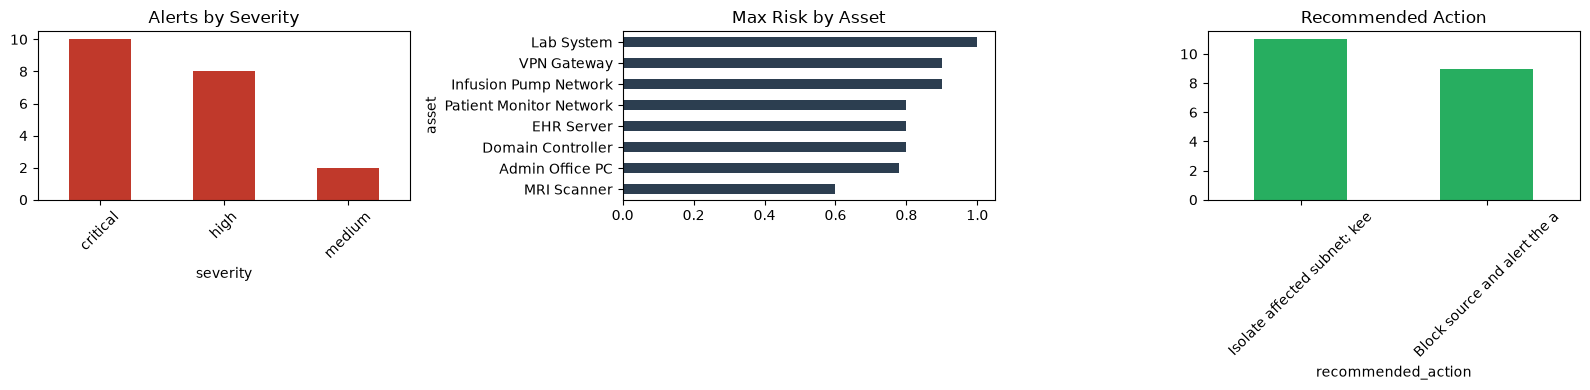

In [20]:
# 9. Dashboard view (charts)
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    
    # Chart 1: Alert severity distribution
    df_alerts["severity"].value_counts().plot.bar(
        ax=ax[0], title="Alerts by Severity", color="#c0392b", rot=45
    )
    
    # Chart 2: Max risk score by asset
    df_fused.groupby("asset")["risk_score"].max().sort_values().plot.barh(
        ax=ax[1], title="Max Risk by Asset", color="#2c3e50"
    )
    
    # Chart 3: Recommended action distribution
    df_fused["recommended_action"].str.slice(0, 28).value_counts().plot.bar(
        ax=ax[2], title="Recommended Action", color="#27ae60", rot=45
    )
    
    plt.tight_layout()
    print("✓ Dashboard charts rendered")
    plt.show()
except Exception as e:
    print(f"⚠ Charts unavailable: {e}")

## Cell 10: Final Readiness Report

In [21]:
# 10. Final readiness report
print("\n" + "=" * 70); print("READINESS REPORT"); print("=" * 70)
checks = {
    "Rule engine + simulation": len(df_alerts) > 0,
    "Shared 9-column contract valid": len(problems) == 0,
    "engine/alerts.csv written": (ROOT / "engine" / "alerts.csv").exists(),
    "Threat intel loaded": ti is not None and len(ti.BAD_SET) > 0,
    "Network model scored (%s)" % model_status.get("backend", "-"): model_status.get("ok", False),
    "Log-anomaly model scored": anomaly_status.get("ok", False),
    "Models actually used in fusion": (df_fused["network_source"].str.startswith("model").any() and anomaly is not None),
    "FastAPI backend + auth": server is not None and api_ok,
}
for label, passed in checks.items():
    print(f"{'✓ PASS' if passed else '✗ MISSING':12} {label}")
print("=" * 70)
if server is not None:
    server.terminate()


READINESS REPORT
✓ PASS       Rule engine + simulation
✓ PASS       Shared 9-column contract valid
✓ PASS       engine/alerts.csv written
✓ PASS       Threat intel loaded
✓ PASS       Network model scored (snapml)
✓ PASS       Log-anomaly model scored
✓ PASS       Models actually used in fusion
✓ PASS       FastAPI backend + auth


## Instructions : Starting up the frontend

1. Make sure the notebook has run first (generates the alerts in the database)

2. Open a terminal in JupyterLab and run:

<code> bash
cd ~/Datathon-SOC
python -m uvicorn soc.main:app --host 0.0.0.0 --port 8000</code>

You should see:

INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)

3. Access the dashboard:

From the VM: http://localhost:8000
From another machine: http://<vm-ip>:8000 (where vm-ip is the VM’s IP address)

4. Login with your access token:

Open .env and copy the SOC_ANALYST_TOKEN value
Paste it into the “Access token” field on the login page
Click “Sign in”
Shutting Down

When you’re done, run:

<code>bash
bash scripts/shutdown.sh</code>


## Important note on frontend

The front end may not be able to be accessed through this method as Jupyterlabs most likely has a firewall/proxy restraint.

Hence it is advised to try running on the local environment.